<h1>Creación de Modelos Predictivos</h1>
<p>
En la actualidad, las organizaciones generan grandes volúmenes de datos sobre el comportamiento de sus clientes y sobre las condiciones en que opera su negocio. La minería de datos permite convertir esa información en conocimiento útil, y los modelos predictivos son una de sus herramientas centrales, ya que estiman eventos futuros a partir de patrones observados en datos históricos. Dentro de la Inteligencia de Negocios, estos modelos apoyan decisiones como a qué clientes dirigir una campaña, cuánto inventario preparar o cómo asignar recursos de forma más eficiente.
Esta práctica aplica esos conceptos a dos problemas reales de la UCI Machine Learning Repository.
<br><br>
El primero es un problema de clasificación sobre el conjunto Online Shoppers Purchasing Intention, cuyo objetivo es predecir si una sesión de navegación en una tienda en línea terminará en una compra (Revenue) a partir del comportamiento del usuario, las métricas de las páginas visitadas y el contexto de la visita. El segundo es un problema de regresión sobre el conjunto Seoul Bike Sharing Demand, que busca estimar el número de bicicletas alquiladas por hora considerando las condiciones meteorológicas y temporales.
<br><br>
Para el problema de clasificación se construyen y comparan dos algoritmos, Naive Bayes y Árbol de Decisión. Se evalúan mediante exactitud, precisión, recall y F1-score, con el cálculo manual de las métricas a partir de las matrices de confusión y una validación cruzada estratificada de cinco folds. Para el problema de regresión se desarrollan una Regresión Lineal Múltiple y un Árbol de Decisión para Regresión, con una partición cronológica de los datos y la evaluación con MAE, RMSE y R². En ambos casos se aplican las etapas del proceso de minería de datos: exploración de los datos, preparación y transformación de variables (escalado estándar de las numéricas y codificación dummy de las categóricas), modelado y evaluación.
<br><br>
El objetivo no es solo obtener modelos con buen desempeño, sino interpretar sus resultados desde la perspectiva de la Inteligencia de Negocios. Para ello se analizan las consecuencias que tienen los distintos tipos de error en cada contexto, se justifica la selección del modelo más adecuado y se reflexiona sobre la utilidad práctica de las predicciones y sus limitaciones.     
</p>

<h2>Importar las Librerías Necesarias</h2>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_validate
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)

<h2>Funciones de Utilidades Generales</h2>

<b>Nombre:</b> descripcion_estadistica_numerica <br>
<b>Argumentos:</b> <br>
    <b>(DataFrame) df:</b> Representa el dataframe que contiene los datos. <br>
    <b>(String) columna:</b> Representa la columna numérica que se va a utilizar para obtener las medidas. <br>
<b>Objetivo: </b> Mostrar los valores estadísticos más importantes de una columna númerica (media, mínimo, máximo, rango, desviación estándar). <br>
<b>Retorno: </b>-

In [2]:
def descripcion_estadistica_numerica(df,columna):
    print("Media de",columna,":",df[columna].mean())
    print("Valor Mínimo de",columna,":",df[columna].min())
    print("Valor Máximo de",columna,":",df[columna].max())
    print("Rango de Valores en",columna,"(maximo - minimo):",df[columna].max() - df[columna].min())
    print("Desviación Estándar en",columna,df[columna].std())

<h2>1. Modelos de Clasificación</h2>
<hr>
<p>Los modelos de clasificación son una de las técnicas más utilizadas en la minería de datos. Su propósito es asignar cada observación a una categoría a partir de sus características, aprendiendo de datos históricos cuyo resultado ya se conoce. En esta sección se desarrolla un problema de clasificación binaria con el conjunto de datos Online Shoppers Purchasing Intention, que reúne sesiones de navegación de una tienda en línea.
</p>

In [3]:
df_clasificacion = pd.read_csv("online_shoppers_intention.csv")

<h3>1.1 Exploración de la Fuente de Datos</h3>
<p>Antes de iniciar el proceso de preparación es necesario conocer ciertos aspectos de la fuente de datos. En este caso se evaluaron los siguientes aspectos para saber el nivel de calidad de los datos existentes y si es necesario aplicar alguna transformación para realizar correcciones a alguno de los datos.</p>

<b>Consideraciones de Análisis de Calidad de los Datos</b>
<ul>
    <li>Validar la existencia de los valores nulos.</li>
    <li>Validar que los tipos de datos sean consistentes con la información que almacenan.</li>
    <li>Validar que las variables categóricas que almacenan texto no tengan conflictos tipográficos.</li>
</ul>

In [4]:
print("Cantidad de valores vacios en cada columna:")
df_clasificacion.isna().sum()

Cantidad de valores vacios en cada columna:


Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64

In [5]:
print("Información de los tipos de datos y valores no nulos:")
df_clasificacion.info()

Información de los tipos de datos y valores no nulos:
<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 no

In [6]:
print("Validación de los valores de las variables categóricas:")
print("Valores de Month: ",df_clasificacion["Month"].unique())
print("Valores de VisitorType: ",df_clasificacion["VisitorType"].unique())

Validación de los valores de las variables categóricas:
Valores de Month:  <ArrowStringArray>
['Feb', 'Mar', 'May', 'Oct', 'June', 'Jul', 'Aug', 'Nov', 'Sep', 'Dec']
Length: 10, dtype: str
Valores de VisitorType:  <ArrowStringArray>
['Returning_Visitor', 'New_Visitor', 'Other']
Length: 3, dtype: str


<b>Consideraciones de la Exploración Estadística</b>
<ul>
    <li>Visualizar la media, valor mínimo, valor máximo y el rango de valores que tienen algunas columnas numéricas importantes.</li>
    <li>Utilizar visualizaciones para conocer algunos patrones que pueden ser de interes.</li>
    <li>Validar la correlación entre las variables numéricas involucradas.</li>
    <li>Validar la distribución de los datos de la variable objetivo para conocer como los datos se distribuiran antes de realizar la estratificación en el modelo.</li>
</ul>

In [7]:
descripcion_estadistica_numerica(df_clasificacion,"ProductRelated_Duration")

Media de ProductRelated_Duration : 1194.7462199688268
Valor Mínimo de ProductRelated_Duration : 0.0
Valor Máximo de ProductRelated_Duration : 63973.52223
Rango de Valores en ProductRelated_Duration (maximo - minimo): 63973.52223
Desviación Estándar en ProductRelated_Duration 1913.6692878720035


In [8]:
descripcion_estadistica_numerica(df_clasificacion,"Administrative")

Media de Administrative : 2.3151662611516626
Valor Mínimo de Administrative : 0
Valor Máximo de Administrative : 27
Rango de Valores en Administrative (maximo - minimo): 27
Desviación Estándar en Administrative 3.3217841061569113


In [9]:
descripcion_estadistica_numerica(df_clasificacion,"ProductRelated")

Media de ProductRelated : 31.731467964314678
Valor Mínimo de ProductRelated : 0
Valor Máximo de ProductRelated : 705
Rango de Valores en ProductRelated (maximo - minimo): 705
Desviación Estándar en ProductRelated 44.47550330493652


In [10]:
descripcion_estadistica_numerica(df_clasificacion,"Informational")

Media de Informational : 0.5035685320356853
Valor Mínimo de Informational : 0
Valor Máximo de Informational : 24
Rango de Valores en Informational (maximo - minimo): 24
Desviación Estándar en Informational 1.270156425983391


In [11]:
print("Distribución de los Valores de Revenue:")
print(df_clasificacion.groupby("Revenue")["Revenue"].count())

Distribución de los Valores de Revenue:
Revenue
False    10422
True      1908
Name: Revenue, dtype: int64


Text(0.5, 1.0, 'Distribución de Revenue según VisitorType')

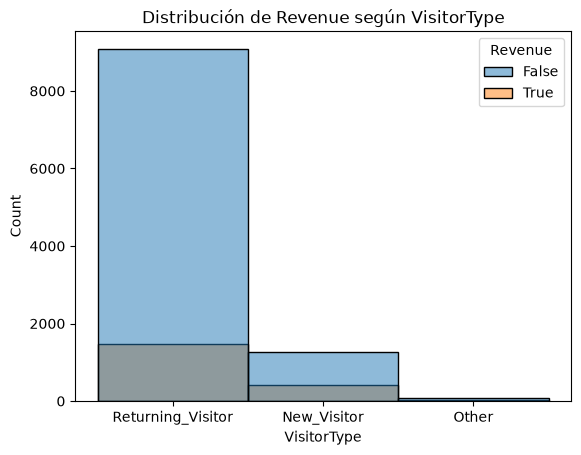

In [12]:
sns.histplot(data=df_clasificacion,x="VisitorType",hue="Revenue",bins=15).set_title("Distribución de Revenue según VisitorType")

Text(0.5, 1.0, 'Distribución de Revenue según Month')

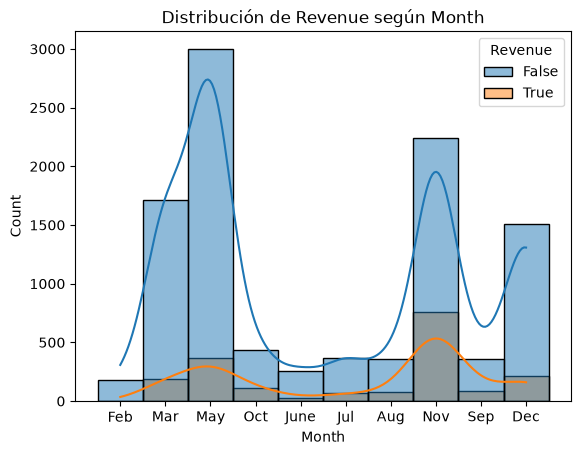

In [13]:
sns.histplot(data=df_clasificacion,x="Month",hue="Revenue",bins=15,kde=True).set_title("Distribución de Revenue según Month")

Text(0.5, 1.0, 'Duración en Páginas de Producto vs Tasa de Salida')

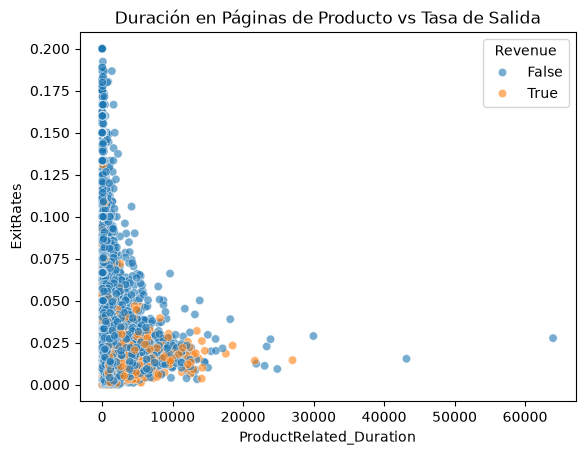

In [14]:
(sns.scatterplot(data=df_clasificacion, x='ProductRelated_Duration', y='ExitRates', hue='Revenue', alpha=0.6)
 .set_title("Duración en Páginas de Producto vs Tasa de Salida"))

Text(0.5, 1.0, 'Correlación entre métricas web')

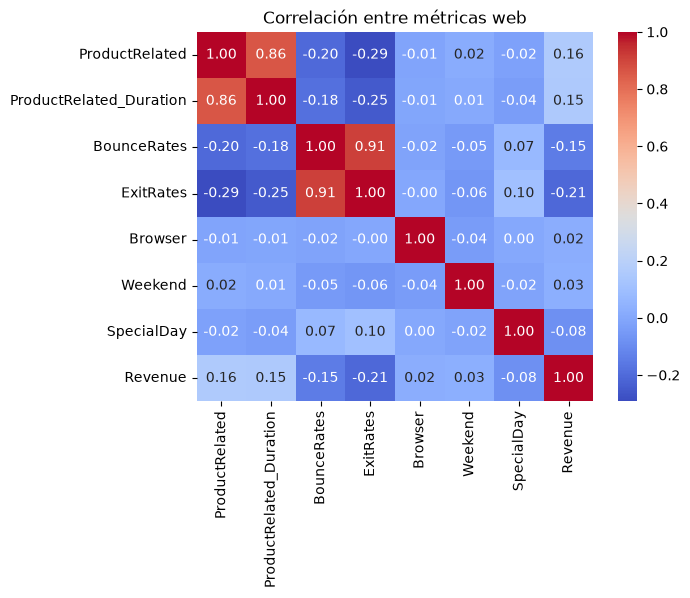

In [15]:
cols_num = ["ProductRelated", "ProductRelated_Duration","BounceRates","ExitRates","Browser","Weekend","SpecialDay","Revenue"]
sns.heatmap(df_clasificacion[cols_num].corr(), annot=True, cmap='coolwarm', fmt=".2f").set_title("Correlación entre métricas web")

<b>Conclusiones de la Exploración de la Fuente de Datos</b>
<p>
El conjunto de datos contiene 12,330 sesiones de navegación y 18 variables. La revisión de calidad no encontró valores nulos en ninguna columna, y los tipos de datos son consistentes con la información que almacenan (7 enteros, 7 decimales, 2 booleanos y 2 textos). Las variables categóricas Month y VisitorType no presentan conflictos tipográficos. Month abarca 10 meses del año (no aparecen enero ni abril) y VisitorType tiene tres categorías: Returning_Visitor, New_Visitor y Other. Por lo tanto, no fue necesario aplicar correcciones sobre los datos.
    
En la exploración estadística se observó que la actividad se concentra en las páginas de productos. ProductRelated tiene una media de 31.73 páginas por sesión, con un máximo de 705 y una desviación estándar de 44.48. Esto indica una distribución muy dispersa y sesgada hacia la derecha, con sesiones muy largas que coexisten con otras de muy poca actividad. Las páginas administrativas (media de 2.32) e informativas (media de 0.50) tienen un uso mucho menor, y en ambos casos la desviación estándar supera a la media.

La variable objetivo Revenue está desbalanceada: 10,422 sesiones (84.5 %) no terminaron en compra frente a 1,908 (15.5 %) que sí lo hicieron. Por esto, al construir los modelos es necesario estratificar la partición entre entrenamiento y prueba, y no basarse únicamente en la exactitud para evaluar su desempeño.

La mayoría de las sesiones corresponden a visitantes recurrentes, que concentran también el mayor número absoluto de compras. Sin embargo, la categoría de nuevos visitantes se encuentra más balanceada, haciendo que una mayor cantidad de los escenarios los nuevos visitantes realicen una sesión que concluya en una compra. La categoría de otros es una categoría marginal por lo tanto no se registran tantas sesiones provenientes de este grupo.

El mayor volumen de sesiones se da en mayo, pero noviembre registra el mayor número de compras y la mayor proporción de conversión, con aproximadamente una compra por cada tres sesiones sin compra. Marzo y diciembre también tienen tráfico alto, mientras que febrero, junio, julio y agosto son meses de baja actividad. El pico de noviembre es consistente con el efecto de eventos comerciales masivos, aunque esa explicación proviene de conocimiento externo y no de los datos.

Las sesiones con compra se concentran en tasas de salida bajas (por debajo de 0.05) y se extienden hacia duraciones más largas. Las tasas de salida altas (por encima de 0.10) corresponden casi exclusivamente a sesiones sin compra con poco tiempo en páginas de producto. Hay una correlación muy alta entre ProductRelated y ProductRelated_Duration (0.86) y entre BounceRates y ExitRates (0.91), por lo que estos pares aportan información redundante. Respecto a Revenue, las relaciones son débiles: positivas con ProductRelated (0.16) y ProductRelated_Duration (0.15), y negativas con ExitRates (-0.21), BounceRates (-0.15) y SpecialDay (-0.08). Browser y Weekend casi no se asocian con la compra.

En conjunto, los datos están limpios y listos para modelar, y la compra se asocia con una mayor interacción con productos, menores tasas de salida y rebote, y con la temporada (en especial noviembre). Ninguna variable numérica por sí sola explica la compra, lo que justifica usar modelos multivariados como Naive Bayes y árboles de decisión. Además, el desbalance de Revenue obliga a evaluar con métricas como precisión, sensibilidad y F1, y no solo con exactitud si se desea tomar una decisión más apropiada cuando se comparen los modelos.
</p>

<h3>1.2 Identificación de las Variables</h3>
<p>
El conjunto de datos para este modelo de clasificación está compuesto por 10 atributos numéricos y 8 categóricos, destacando por no presentar ningún valor faltante en sus registros según lo obtenido en el análisis exploratorio. El objetivo principal del modelo es predecir la variable "Revenue", la cual es de tipo binario y actúa como la etiqueta de clase, indicando si una sesión finalizó o no en una transacción comercial.
    
Un grupo fundamental de características se basa en el comportamiento de navegación del usuario, cuyos valores se derivan de la información de la URL de las páginas y se actualizan en tiempo real a medida que el visitante interactúa con el sitio. Entre estas características se encuentran las variables de tipo entero "Administrative", "Informational" y "ProductRelated", que representan el número exacto de páginas administrativas, informativas y relacionadas con productos que fueron visitadas en una sesión. Asociadas a estas métricas de cantidad, las variables "Administrative_Duration" (entero), "Informational_Duration" (entero) y "ProductRelated_Duration" (continuo) cuantifican el tiempo total que el usuario invirtió navegando dentro de cada una de esas categorías específicas.

El conjunto también incorpora métricas para evaluar el rendimiento de cada página del sitio de comercio electrónico. La variable continua "BounceRates" hace referencia al porcentaje de visitantes que entran al sitio web desde una página determinada y luego se van sin generar ninguna otra solicitud al servidor de análisis durante esa misma sesión. Por su parte, la característica continua "ExitRates" se calcula analizando todas las visualizaciones de una página para determinar el porcentaje de veces que dicha página fue la última de la sesión. Adicionalmente, se incluye la variable de tipo entero "PageValues", la cual representa el valor promedio de una página web que un usuario visitó justo antes de completar con éxito una transacción comercial.

El aspecto temporal y la influencia de las fechas festivas también están fuertemente capturados en la fuente de datos. La característica de tipo entero "SpecialDay" indica qué tan cerca está la fecha de visita a un día especial (como el Día de San Valentín o el Día de las Madres), considerando que en estas fechas las sesiones tienen una mayor probabilidad de culminar en una venta según las dinámicas de entrega y pedidos. Complementando este contexto temporal, se registran el mes del año a través de la variable categórica "Month" y un indicador binario llamado "Weekend", que especifica si la visita del usuario se llevó a cabo durante el fin de semana.

Finalmente, el dataset también contempla información técnica y demográfica sobre el perfil del usuario. Esto se logra mediante el uso de variables de tipo entero como "OperatingSystems", "Browser", "Region" y "TrafficType", que identifican el sistema operativo utilizado, el navegador web, la región geográfica de origen y la fuente o tipo de tráfico que dirigió al visitante al sitio web. A esto se suma la variable categórica "VisitorType", la cual clasifica al usuario para diferenciar si se trata de un visitante nuevo o de alguien recurrente en la plataforma.
</p>

<table style="border-collapse: collapse; width: 100%;">
  <caption style="text-align: left; font-weight: bold; padding: 6px 0;">Tabla de Variables</caption>
  <thead>
    <tr>
      <th style="border: 1px solid gray; padding: 6px; text-align: left;">Nombre</th>
      <th style="border: 1px solid gray; padding: 6px; text-align: left;">Rol</th>
      <th style="border: 1px solid gray; padding: 6px; text-align: left;">Tipo</th>
      <th style="border: 1px solid gray; padding: 6px; text-align: left;">Valores Faltantes</th>
    </tr>
  </thead>
  <tbody>
    <tr><td style="border: 1px solid gray; padding: 6px;">Administrative</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Entero</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">Administrative_Duration</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Flotante</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">Informational</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Entero</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">Informational_Duration</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Flotante</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">ProductRelated</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Entero</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">ProductRelated_Duration</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Flotante</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">BounceRates</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Flotante</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">ExitRates</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Flotante</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">PageValues</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Flotante</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">SpecialDay</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Decimal</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">Month</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Texto</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">OperatingSystems</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Entero</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">Browser</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Entero</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">Region</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Entero</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">TrafficType</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Entero</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">VisitorType</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Texto</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">Weekend</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Booleano</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">Revenue</td><td style="border: 1px solid gray; padding: 6px;">Objetivo</td><td style="border: 1px solid gray; padding: 6px;">Booleano</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
  </tbody>
</table>
<i>Tabla de variables identificadas en Online Shoppers Purchasing Intention (UCI).</i>

<h3>1.3 Variable Objetivo del Problema</h3>
<p>
El objetivo principal de la creación del modelo de clasificación es predecir de manera precisa si la sesión de un usuario en el sitio de comercio electrónico finalizará en una transacción, utilizando la variable binaria "Revenue" como etiqueta de clase a predecir. Al evaluar el comportamiento de navegación en tiempo real, el perfil del visitante y las métricas de interacción recopiladas, el algoritmo debe aprender los patrones y comportamientos específicos que diferencian a un comprador de un visitante que abandona la página sin comprar.
    
Desde un punto de vista analítico y comercial, el propósito de clasificar de forma predictiva estas interacciones puede ofrecer una gran variedad de beneficios, con esto se busca transformar los datos crudos de tráfico web y características de sesión en información estratégica y accionable. Al identificar qué características o combinaciones de variables son más determinantes para concretar una venta, el modelo puede proporcionar información valiosa para que el negocio pueda optimizar la experiencia del usuario, retener clientes potenciales y diseñar estrategias orientadas a maximizar la tasa de conversión general del sitio.

</p>

<h3>1.4 Preparación y Preprocesamiento de los Modelos</h3>
<p>Para crear los modelos de clasificación se debe considerar que en el análisis exploratorio se encontró que los valores de Revenue que es la variable que se desea predecir estan distribuidos de forma desigual, por lo tanto al momento de crear el modelo se debe considerar que el conjunto de datos de prueba y de entrenamiento debe estratificarse para que el resultado del modelo considere de forma proporcional los datos que tiene la fuente de datos original.</p>
<p>En esta primera etapa utilizando <code>train_test_split</code> se van extraer los datos que serviran para entrenamiento y prueba de los modelos, en este caaso se aplicó una estratificación que toma como referencia la variable Revenue (y_clasificacion) y se aplicará una distribución donde un 20% del conjunto de datos será utilizado para pruebas y un 80% será utilizado para entrenamiento.</p>

In [16]:
X_clasificacion = df_clasificacion.drop(columns='Revenue')
y_clasificacion = df_clasificacion['Revenue'].astype(int)

In [17]:
X_trainclass, X_testclass, y_trainclass, y_testclass = train_test_split(X_clasificacion, y_clasificacion, test_size=0.2
                                                                        , random_state=42, stratify=y_clasificacion)

<p>Para que los modelos de clasificación utilicen correctamente las variables categóricas, se debe considerar que, por su naturaleza, estos algoritmos solo pueden procesar valores numéricos. Por ello, es necesario aplicar técnicas de codificación que conviertan las categorías en una representación numérica sin introducir órdenes o jerarquías que no existen entre ellas. Para esto, primero se deben identificar cuáles variables son categóricas y cuáles son numéricas, de manera que a cada grupo se le aplique la transformación que le corresponde.</p>

In [18]:
columnas_categoricas = ['Month', 'VisitorType', 'Weekend', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']
columnas_numericas = [c for c in X_clasificacion.columns if c not in columnas_categoricas]
print("Columnas Numéricas:", columnas_numericas)
print("Columnas Categóricas:", columnas_categoricas)

Columnas Numéricas: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']
Columnas Categóricas: ['Month', 'VisitorType', 'Weekend', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']


Las variables numéricas se escalan con <b>StandardScaler</b>, una técnica que transforma cada característica para que tenga media 0 y desviación estándar 1. Esto evita que las variables con rangos amplios, como ProductRelated_Duration, dominen sobre las de rangos pequeños. Este escalado se aplicó a todas las columnas numéricas de tipo entero y flotante.

Las variables categóricas, como Month y VisitorType, toman valores en forma de texto que los modelos no pueden procesar directamente. Para resolverlo se aplica una dummificación con <b>OneHotEncoder</b>, que reemplaza cada variable categórica por varias columnas binarias, una por categoría. En cada fila, la columna correspondiente a la categoría observada toma el valor 1 y las demás toman el valor 0. Así, la información categórica queda en formato numérico sin asignar un orden artificial entre las categorías.

Una vez definidas las variables numéricas y las categóricas, se utiliza el objeto <b>ColumnTransformer</b>, que permite aplicar cada transformación solo a su grupo de columnas: el escalado estándar a las numéricas y la dummificación a las categóricas. De esta forma, ambos procesos se ejecutan de manera conjunta y ordenada sobre el conjunto de datos.


In [19]:
def crear_preprocesador():
    return ColumnTransformer(transformers=[
        ('num', StandardScaler(), columnas_numericas),
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='if_binary', sparse_output=False), columnas_categoricas)
    ])

<h3>1.5 Construcción de los Modelos</h3>
<p>Luego de que se realizó el preprocesamiento, se construyen dos modelos con <b>scikit-learn</b> sobre la partición 80 % / 20 % estratificada que se definió anteriormente. En este apartado se realizará simplemente la operación de entrenamiento con Naive Bayes y con Árboles Decisorios. Para el proceso de entrenamiento se incluyó en un Pipeline la secuencia de pasos que debe implementar cada modelo, para así asegurar que la etapa de preprocesamiento se realice antes que el proceso de entrenamiento.</p>


<b>Entrenamiento del Modelo de Clasificación por Naive Bayes</b>


In [20]:
modelo_nb = Pipeline([('prep', crear_preprocesador()), ('clf', GaussianNB())])
modelo_nb.fit(X_trainclass, y_trainclass)
pred_nb = modelo_nb.predict(X_testclass)

<b>Funciones Auxiliares para Entrenamiento</b>

<b>Nombre:</b> calcular_min_samples_leaf <br>
<b>Argumentos:</b> <br>
    <b>(int) n_muestras:</b> Representa la cantidad total de muestras que se tomaran de referencia. <br>
    <b>(float) proporcion:</b> Representa la cantidad de elementos que se tomaran como referencia en base al total. (0.5% base) <br>
    <b>(int) minimo:</b> Representa la cantidad mínimo de casos que debería tomar una hoja. (5 base) <br>
<b>Objetivo: </b> Obtener la cantidad de mínima de ejemplares necesarios que debería tener una hoja. <br>
<b>Retorno:</b> (int) Retorna la cantidad mínima de ejemplares necesarios en una hoja que se necesitan para que representen un porcentaje proporcional.

In [21]:
def calcular_min_samples_leaf(n_muestras, proporcion=0.005, minimo=5):
    return max(minimo, int(np.ceil(n_muestras * proporcion)))

<b>Entrenamiento del Modelo de Clasificación por Árboles Decisorios</b>
<p>Para los árboles decisorios se consideró que la profundidad máxima del árbol sea 5 para evitar definiciones demasiado específicas en el proceso de entrenamiento y se estableció que cada hoja necesita un mínimo de 0.5% de ejemplares del conjunto de datos total de entrenamiento, para evitar que el modelo tienda a utilizar reglas que sean en base a escenarios muy escasos. En este caso se utilizó un método calculado para obtener la cantidad de ejemplares mínimos ya que ofrece un escenario más flexible en caso de que la fuente de datos crezca posteriormente, la proporción utilizada tiene algo de riesgo de sobreajuste pero es una aproximación razonable ya que utilizar una proporción de 0.1% o 0.2%  puede producir reglas que no suceden con frecuencia y utilizar una proporción de 1% puede crear un subajuste que termine en hojas mucho más generales e incluso evidentes. </p>

In [22]:
min_leaf = calcular_min_samples_leaf(len(X_trainclass))

modelo_dt = Pipeline([('prep', crear_preprocesador()),
                      ('clf', DecisionTreeClassifier(max_depth=5, min_samples_leaf=min_leaf, random_state=42))])
modelo_dt.fit(X_trainclass, y_trainclass)
pred_dt = modelo_dt.predict(X_testclass)

<h3>Funciones para Evaluación de los Modelos</h3>

<b>Nombre:</b> metricas_manuales <br>
<b>Argumentos:</b> <br>
    <b>(Series) y_real:</b> Representa el valor real que tiene la variable y en el dataframe. <br>
    <b>(Series) y_pred:</b> Representa los valores obtenidos mediante las predicciones del modelo. <br>
<b>Objetivo: </b> Obtener las métricas manuales que corresponden a métodos de evaluación del modelo y la matriz de confusión. <br>
<b>Retorno:</b> (Dictionary) Retorna un conjunto de valores ordenados de forman clave-valor que representan los resultados obtenidos de cada una de las métricas.

In [23]:
def metricas_manuales(y_real, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_real, y_pred).ravel()
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
    return {'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
            'Accuracy': accuracy, 'Precision': precision, 'Recall': recall, 'F1': f1}


<b>Nombre:</b> comparar_manual_vs_sklearn <br>
<b>Argumentos:</b> <br>
    <b>(String) nombre:</b> Representa el nombre del modelo que se va a utilizar en la comparación. <br>
    <b>(Series) y_real:</b> Representa el valor real que tiene la variable y en el dataframe. <br>
    <b>(Series) y_pred:</b> Representa los valores obtenidos mediante las predicciones del modelo. <br>
<b>Objetivo: </b> Comparar los resultados de las métricas manuales y las métricas de sklearn e imprimir el resultado <br>
<b>Retorno:</b> (Dictionary) Retorna un conjunto de valores ordenados de forman clave-valor que representan los resultados obtenidos de cada una de las métricas.

In [24]:
def comparar_manual_vs_sklearn(nombre, y_real, y_pred):
    m = metricas_manuales(y_real, y_pred)
    sk = {'Accuracy': accuracy_score(y_real, y_pred), 'Precision': precision_score(y_real, y_pred),
          'Recall': recall_score(y_real, y_pred), 'F1': f1_score(y_real, y_pred)}
    tabla = pd.DataFrame({'Manual': {k: m[k] for k in sk}, 'scikit-learn': sk})
    tabla['Diferencia'] = (tabla['Manual'] - tabla['scikit-learn']).abs()
    print(f"=== {nombre} ===")
    print(f"TN={m['TN']}  FP={m['FP']}  FN={m['FN']}  TP={m['TP']}")
    display(tabla.round(4))
    return m

<b>Nombre:</b> graficar_matriz_confusion <br>
<b>Argumentos:</b> <br>
    <b>(String) nombre:</b> Representa el nombre del modelo que se va a utilizar en la comparación. <br>
    <b>(Series) y_real:</b> Representa el valor real que tiene la variable y en el dataframe. <br>
    <b>(Series) y_pred:</b> Representa los valores obtenidos mediante las predicciones del modelo. <br>
<b>Objetivo: </b> Graficar la matriz de confusión de un modelo. <br>
<b>Retorno:</b> -

In [47]:
def graficar_matriz_confusion(nombre, y_real, y_pred):
    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay.from_predictions(
        y_real, y_pred,
        display_labels=['No compra', 'Compra'],
        cmap='Blues', ax=ax, colorbar=True,
        normalize=None,
        values_format='d'
    )
    ax.set_title(f"Matriz de confusión - {nombre}")
    plt.tight_layout()
    plt.show()


<h3>1.6 Evaluación de los Modelos de Clasificación</h3>

<i>Observaciones</i>

Para estos escenarios se tomo como positivo el caso donde sucede una compra y como negativo aquellos casos donde una sesión no concluye en compra, por lo tanto, la asociación de TP, FP, TN, FN corresponde de la siguiente forma:

<b>TP</b> corresponde a esos casos donde el modelo definió que era una compra y efectivamente fue una.

<b>FP</b> corresponde a esos casos donde el modelo definió que era una compra y la sesión realmente no concluyó en una.

<b>TN</b> corresponde a esos casos donde el modelo definió que no era una compra y la sesión realmente no concluyó en una.

<b>FN</b> corresponde a esos casos donde el modelo definió que no era una compra y la sesión realmente si fue una compra.

<p>Para evaluar los resultados de los modelos, luego de que realicen las predicciones se tomaron en cuenta un conjunto de métricas que permiten conocer el comportamiento del modelo y así poder determinar si el resultado logrado es el apropiado, las métricas que se están considerando son las siguientes: </p>
<ul>
    <li><b>Exactitud</b> = (TP + TN) / (TP + TN + FP + FN)</li>
    <li><b>Precisión</b> = TP / (TP + FP)</li>
    <li><b>Recall</b> = TP / (TP + FN)</li>
    <li><b>F1</b> = 2 · Precisión · Recall / (Precisión + Recall)</li>
</ul>

Estas medidas se obtuvieron experimentalmente de dos fuentes diferentes, la primera calculando manualmente las métricas utilizando la función <code> metricas_manuales</code> que se encuentra en el apartado de Funciones Manuales para evaluación de los modelos y luego se obtuvieron utilizando las funciones predefinidas por sklearn que sirven para conocer el comportamiento del modelo.

<b>Resultados Evaluativos de Naive Bayes</b>

In [26]:
m_nb = comparar_manual_vs_sklearn("Naive Bayes", y_testclass, pred_nb)

=== Naive Bayes ===
TN=302  FP=1782  FN=10  TP=372


,Manual,scikit-learn,Diferencia
Accuracy,0.2733,0.2733,0.0
Precision,0.1727,0.1727,0.0
Recall,0.9738,0.9738,0.0
F1,0.2934,0.2934,0.0


In [27]:
print("Naive Bayes\n", classification_report(y_testclass, pred_nb, target_names=['No compra', 'Compra']))

Naive Bayes
               precision    recall  f1-score   support

   No compra       0.97      0.14      0.25      2084
      Compra       0.17      0.97      0.29       382

    accuracy                           0.27      2466
   macro avg       0.57      0.56      0.27      2466
weighted avg       0.84      0.27      0.26      2466



<b>Interpretación de las Métricas de Naive Bayes</b>

Luego de ejecutar las métricas correspondientes a Naive Bayes se puede decir que este modelo no es una opción apropiada en general. La exhaustividad (recall) de la clase <code>Compra</code> es muy elevada, con un 97.38 %, pero esta métrica por sí sola no es de confianza. Al revisar más detalladamente los datos se observa que el modelo marcó un total de 2,154 sesiones (TP + FP) como compras, lo que equivale a cerca del 87 % de las sesiones de prueba, cuando solo el 15.5 % realmente terminó en compra. Es decir, el recall es alto porque el modelo clasifica casi todo como compra y detecta 372 de las 382 compras reales (solo 10 falsos negativos), pero lo hace a costa de generar 1,782 falsos positivos.

La exactitud (accuracy) confirma este problema ya que el modelo solo logró un 27.33 %, un resultado muy deficiente, incluso inferior al de un modelo trivial que dijera que todas las sesiones conducen a no compra, el cual alcanzaría una exactitud mayor por la distribución de los datos. En términos de precisión, el modelo obtiene un 17.27 %, lo que significa que solo 17 de cada 100 sesiones que predice como compra lo son realmente. Este valor es casi igual a la proporción de compradores en los datos (15.5 %), por lo que la predicción de compra casi no aporta información frente a elegir sesiones al azar. El F1-score de la clase <code>Compra</code> es de 0.2934, y refleja que el recall alto no compensa la baja precisión.

Al analizar la clase <code>No compra</code> se observa el mismo comportamiento en sentido inverso. Su precisión es alta (0.97), pero su recall es de solo 0.14 ya que el modelo identificó correctamente 302 de las 2,084 sesiones sin compra. Su F1-score es de 0.25. La precisión alta en esta clase no indica un buen desempeño, ya que se debe a que el modelo clasifica pocas sesiones como <code>No compra</code> que casi todas las que descarta realmente no compraron, mientras que deja pasar a la gran mayoría.

Los promedios del reporte de clasificación refuerzan esta conclusión. El promedio macro, que da el mismo peso a ambas clases, muestra una precisión de 0.57, un recall de 0.56 y un F1 de 0.27, valores cercanos al azar para un problema de dos clases. El promedio ponderado tiene una precisión de 0.84, que parece alta, pero solo porque la clase <code>No compra</code> tiene mucho más peso en los datos. Su recall de 0.27 coincide con la exactitud. En conjunto, los resultados indican que el modelo no logra distinguir adecuadamente entre sesiones con y sin compra, por lo que no resulta útil para tomar decisiones de negocio.

<b>Matriz de Confusión de Naive Bayes</b>

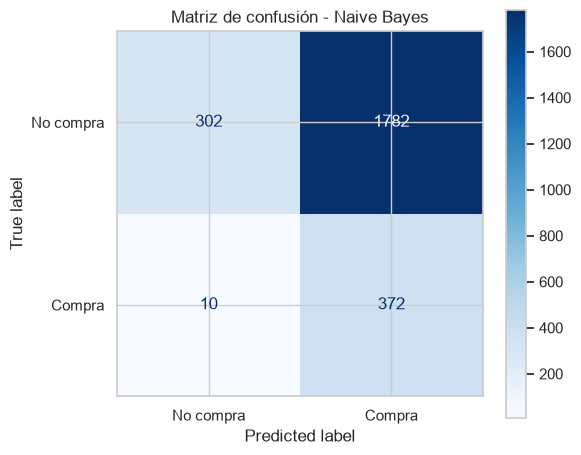

In [48]:
graficar_matriz_confusion('Naive Bayes', y_testclass, pred_nb)

<b>Interpretación de la Matriz de Confusión</b>

La matriz muestra cómo clasificó el modelo las 2466 sesiones de prueba. De las 2,084 sesiones en las que el usuario no compró, el modelo solo identificó correctamente 302 (TN) y se equivocó en 1782, que marcó como compra (FP). En cambio, de las 382 sesiones con compra real, detectó 372 (TP) y solo dejó pasar 10 (FN). Es decir, el modelo casi nunca se equivoca con quienes sí compran, pero lo logra porque etiqueta como compra a la gran mayoría de las sesiones.

Esto se ve en el color de la matriz: la celda más oscura, la de falsos positivos, concentra el mayor número de errores. En la práctica, el modelo predijo compra en 2,154 sesiones (372 + 1782), pero solo 372 eran compras reales, por lo que casi 5 de cada 6 alertas serían alertas falsas de compra. Aunque detecta casi todas las compras, el modelo no distingue bien entre quien compra y quien no.

<b>Justificación de los Resultados de Naive Bayes</b>

Los resultados obtenidos con el modelo no son apropiados por varias razones propias del algoritmo y de los datos utilizados. Naive Bayes Gaussiano estima la probabilidad de cada clase multiplicando las probabilidades individuales de cada variable, y esto solo es válido si se cumplen dos condiciones: que las variables sean condicionalmente independientes entre sí dada la clase, y que las variables numéricas sigan una distribución normal dentro de cada clase. En este conjunto de datos ninguno de los dos se cumple de forma razonable.

En primer lugar, la condicional de independencia se viola por la correlación elevada entre varias variables, como se observó en el análisis exploratorio: BounceRates y ExitRates tienen una correlación de 0.91, y ProductRelated y ProductRelated_Duration de 0.86. Cuando dos variables aportan casi la misma información, el modelo la cuenta dos veces como si fueran evidencias independientes, lo que sobreestima el peso de esas características. Este efecto puede ayudar a explicar por qué el modelo clasificó el 87 % de las sesiones como compra.

En segundo lugar, la condición de normalidad tampoco se cumple. Las variables numéricas presentan distribuciones muy sesgadas, con muchos valores cercanos a cero y algunas sesiones extremas (por ejemplo, ProductRelated llega a 705 páginas con una media de 31.7). Además, el preprocesamiento de dummificiación con OneHotEncoder generó numerosas columnas binarias a partir de Month, VisitorType, Weekend, OperatingSystems, Browser, Region y TrafficType. Una variable binaria no puede seguir una distribución normal, y las categorías poco frecuentes producen columnas casi siempre en cero con una varianza muy pequeña dentro de cada clase. Cuando el modelo evalúa esas columnas, pequeñas diferencias generan probabilidades extremas que distorsionan la decisión final.

En conjunto, estos factores hacen que las probabilidades que calcula el modelo sean poco confiables y que tienda a clasificar casi todas las sesiones en una sola clase, lo que explica el recall de 0.97 junto con una precisión de 0.17 y una exactitud de 0.27. Para verificarlas se podría repetir el entrenamiento eliminando las variables redundantes (por ejemplo, ExitRates y ProductRelated_Duration), usar otro algoritmo para las variables categóricas o combinar tipos de variables con modelos distintos.

<b>Resultados Evaluativos de Arboles Decisorios</b>

In [29]:
m_dt = comparar_manual_vs_sklearn("Árbol de Decisión", y_testclass, pred_dt)

=== Árbol de Decisión ===
TN=1990  FP=94  FN=149  TP=233


,Manual,scikit-learn,Diferencia
Accuracy,0.9015,0.9015,0.0
Precision,0.7125,0.7125,0.0
Recall,0.6099,0.6099,0.0
F1,0.6573,0.6573,0.0


In [30]:
print("Árbol de Decisión\n", classification_report(y_testclass, pred_dt, target_names=['No compra', 'Compra']))

Árbol de Decisión
               precision    recall  f1-score   support

   No compra       0.93      0.95      0.94      2084
      Compra       0.71      0.61      0.66       382

    accuracy                           0.90      2466
   macro avg       0.82      0.78      0.80      2466
weighted avg       0.90      0.90      0.90      2466



<b>Interpretación de las Métricas de Árboles Decisorios</b>

El Árbol de Decisión muestra un desempeño adecuado y es una opción apropiada para este problema. Sobre las 2,466 sesiones de prueba, el modelo clasificó correctamente 1,990 sesiones sin compra (TN) y 233 sesiones con compra (TP), con 94 falsos positivos y 149 falsos negativos. Su exactitud (accuracy) fue de 90.15 %, superior al porcentaje que alcanzaría un modelo que siempre predijera <code>No compra</code>.

En la clase de interés, <code>Compra</code>, la precisión fue de 71.25 %, es decir que cuando el modelo predice una compra, acierta en 7 de cada 10 casos. El recall (exhaustividad) fue de 60.99 %, es decir, detecta alrededor del 61 % de las compras reales y deja pasar el 39 % restante. El F1-score de 0.6573 resume este equilibrio y refleja un desempeño aceptable, aunque mejorable.

En la clase <code>No compra</code> el desempeño es mejor, con precisión de 0.93, recall de 0.95 y F1 de 0.94. Esto se debe a que esta clase representa el 84.5 % de los datos y el modelo tiene más ejemplos para aprender sus patrones. Los promedios del reporte de clasificación lo reflejan: el promedio ponderado (0.90 en las tres métricas) es alto porque hay más ejemplares de esta clase, mientras que el promedio macro (precisión 0.82, recall 0.78, F1 0.80) es más bajo porque da el mismo peso a ambas.

En conjunto, el árbol es confiable para descartar sesiones sin intención de compra y razonablemente preciso al identificar compradores. Su principal limitación es el recall de la clase <code>Compra</code>, al final si el negocio busca no perder oportunidades de venta, casi 4 de cada 10 compras pasarían sin ser detectadas.

<b>Matriz de Confusión de Árbol de Decisión</b>

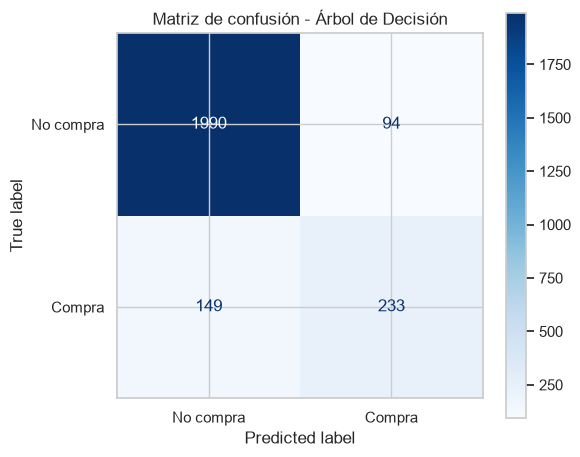

In [49]:
graficar_matriz_confusion('Árbol de Decisión', y_testclass, pred_dt)

<b>Interpretación de la Matriz de Confusión</b>

La matriz muestra que el Árbol de Decisión clasificó correctamente la gran mayoría de las sesiones sin compra: de las 2084 sesiones en las que el usuario no compró, acertó en 1990 (TN) y solo se equivocó en 94, que marcó como compra (FP). Esto se refleja en el color de la matriz, donde la celda más oscura corresponde a los verdaderos negativos. En las sesiones con compra real, el modelo detectó 233 de las 382 (TP) y dejó pasar 149 (FN).

El árbol mantiene un equilibrio entre ambos tipos de error: de las 327 sesiones que predijo como compra (233 + 94), 233 eran reales, por lo que 7 de cada 10 alertas de posibles compras son correctas. Su punto débil son los falsos negativos, ya que casi 4 de cada 10 compras reales no son detectadas. Esto indica que el modelo es confiable cuando predice una compra, pero todavía pierde una parte importante de las oportunidades de venta.

<b>Justificación del Árbol de Decisión</b>

El Árbol de Decisión obtuvo mejores resultados porque su forma de clasificar divide los datos mediante reglas del tipo “si la variable es mayor que cierto valor”, que no exigen independencia ni normalidad. Una variable redundante simplemente deja de ser útil después de usarse en una división, en lugar de contar varias veces como evidencia, y las variables binarias y las numéricas sesgadas se manejan sin problema, ya que el árbol solo busca el mejor punto de corte. Además, el árbol puede capturar relaciones no lineales y combinaciones entre variables. La decisión de compra no depende de una sola característica, sino de interacciones entre ellas, como un número alto de páginas de producto combinado con una tasa de salida baja. Mientras Naive Bayes suma evidencias de cada variable por separado, el árbol evalúa condiciones encadenadas, lo que le permite separar mejor a quienes compran de quienes no.

Por último, las restricciones de profundidad (max_depth) y de tamaño mínimo de hoja (min_samples_leaf) evitaron que el árbol memorizara casos particulares del entrenamiento. Aun así, el árbol tiene una limitación: su recall de 0.61 en la clase <code>Compra</code> muestra que no detecta cerca del 40 % de las compras reales, probablemente por el desbalance de las clases. Por lo tanto, el árbol es una buena opción pero todavia tiene margen de mejora.

<h2>1.7 Validación Estratificada Cruzada</h2>

Para realizar la validación se debe crear un objeto de tipo <code>StratifiedKFold</code> que divida un conjunto de datos en 5 partes. En este caso el objeto sirve para que todas las parten tengan la misma proporción de clases del conjunto original de datos y se puedan lograr resultados más representativos cuando se quiera realizar un entrenamiento ya que la muestra original esta desbalanceada y si se toma de forma aleatoria simplemente puede suceder que existan partes donde no hay una meustra representativa y el caso más drástico que podría pasar por el desbalance es que existan folds que directamente no presenten registros de compra porque la probabilidad de que se seleccione alguno de estos valores de forma aleatoria es más baja.

In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {'accuracy': 'accuracy', 'precision': 'precision', 'recall': 'recall', 'f1': 'f1'}
resultados_cv = {}

<b>Funciones Auxiliares para Validación Cruzada</b>

<b>Nombre:</b> validar_modelo <br>
<b>Argumentos:</b> <br>
    <b>(String) nombre:</b> Representa el nombre del modelo que se va a utilizar en la comparación. <br>
    <b>(GaussianNB | DecisionTreeClassifier) modelo:</b> Representa el modelo que se va a evaluar. <br>
<b>Objetivo: </b> Mostrar una tabla de métricas que describen un modelo al realizar una validación cruzada. <br>
<b>Retorno:</b> -

In [51]:
def validar_modelo(nombre, modelo):
    cv = cross_validate(modelo, X_trainclass, y_trainclass, cv=skf, scoring=scoring)
    resultados_cv[nombre] = cv
    print(f"--- {nombre} ---")
    por_fold = pd.DataFrame({m: cv[f'test_{m}'] for m in scoring},
                            index=[f'Fold {i}' for i in range(1, 6)])
    por_fold.loc['Media'] = por_fold.mean()
    por_fold.loc['Desv. est.'] = por_fold.iloc[:5].std()
    display(por_fold.round(4))

<b>Validación Cruzada con Naive Bayes</b>

In [54]:
validar_modelo('Naive Bayes', modelo_nb)

--- Naive Bayes ---


C:\Users\anton\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\anton\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


,accuracy,precision,recall,f1
Fold 1,0.2681,0.1721,0.9803,0.2929
Fold 2,0.2889,0.1763,0.9803,0.2989
Fold 3,0.2737,0.1732,0.9803,0.2944
Fold 4,0.2879,0.1781,0.9935,0.3020
Fold 5,0.3103,0.1809,0.9803,0.3054
Media,0.2858,0.1761,0.9830,0.2987
Desv. est.,0.0164,0.0036,0.0059,0.0052


<b>Validación Cruzada con Árbol de Decisión</b>

In [56]:
validar_modelo('Árbol de Decisión', modelo_dt)

--- Árbol de Decisión ---


C:\Users\anton\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\anton\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


,accuracy,precision,recall,f1
Fold 1,0.8779,0.6088,0.5869,0.5977
Fold 2,0.8976,0.7085,0.5738,0.6341
Fold 3,0.8900,0.6982,0.5082,0.5882
Fold 4,0.9088,0.7480,0.6209,0.6786
Fold 5,0.9077,0.7158,0.6689,0.6915
Media,0.8964,0.6959,0.5917,0.6380
Desv. est.,0.0129,0.0521,0.0594,0.0464


<b>Resumen de Resultados</b>

In [34]:
resumen_cv = pd.DataFrame({
    nombre: {m: f"{cv[f'test_{m}'].mean():.3f} ± {cv[f'test_{m}'].std():.3f}" for m in scoring}
    for nombre, cv in resultados_cv.items()
})
resumen_cv

,Naive Bayes,Árbol de Decisión
accuracy,0.286 ± 0.015,0.896 ± 0.012
precision,0.176 ± 0.003,0.696 ± 0.047
recall,0.983 ± 0.005,0.592 ± 0.053
f1,0.299 ± 0.005,0.638 ± 0.042


<b>Resultados de Validación Cruzada Estratificada</b>


<b>Matrices de Confusión de los Modelos de Clasificación</b>

In [50]:
sns.set_theme(style="whitegrid")

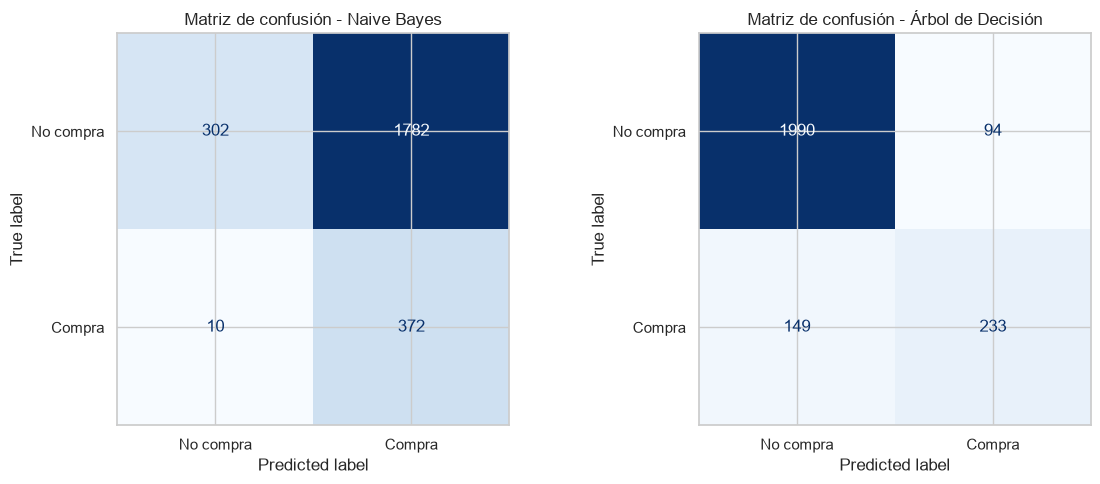

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, nombre, pred in zip(axes, ['Naive Bayes', 'Árbol de Decisión'], [pred_nb, pred_dt]):
    ConfusionMatrixDisplay.from_predictions(y_testclass, pred, display_labels=['No compra', 'Compra'],
                                            cmap='Blues', ax=ax, colorbar=False)
    ax.set_title(f"Matriz de confusión - {nombre}")
plt.tight_layout()
plt.show()

<h3>Comparación de Modelos y Selección</h3>

,Accuracy,Precision,Recall,F1
Naive Bayes,0.2733,0.1727,0.9738,0.2934
Árbol de Decisión,0.9015,0.7125,0.6099,0.6573


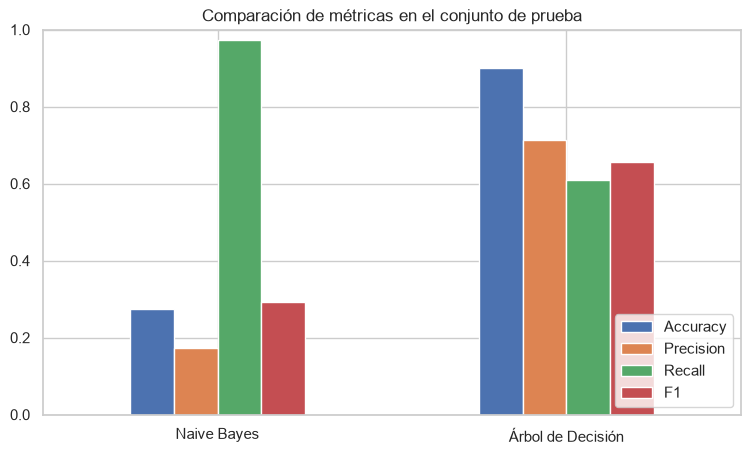

In [35]:
comparacion = pd.DataFrame({
    'Naive Bayes': {k: m_nb[k] for k in ['Accuracy', 'Precision', 'Recall', 'F1']},
    'Árbol de Decisión': {k: m_dt[k] for k in ['Accuracy', 'Precision', 'Recall', 'F1']}
}).T
display(comparacion.round(4))

comparacion.plot(kind='bar', figsize=(9, 5), rot=0)
plt.title("Comparación de métricas en el conjunto de prueba")
plt.ylim(0, 1)
plt.legend(loc='lower right')
plt.show()

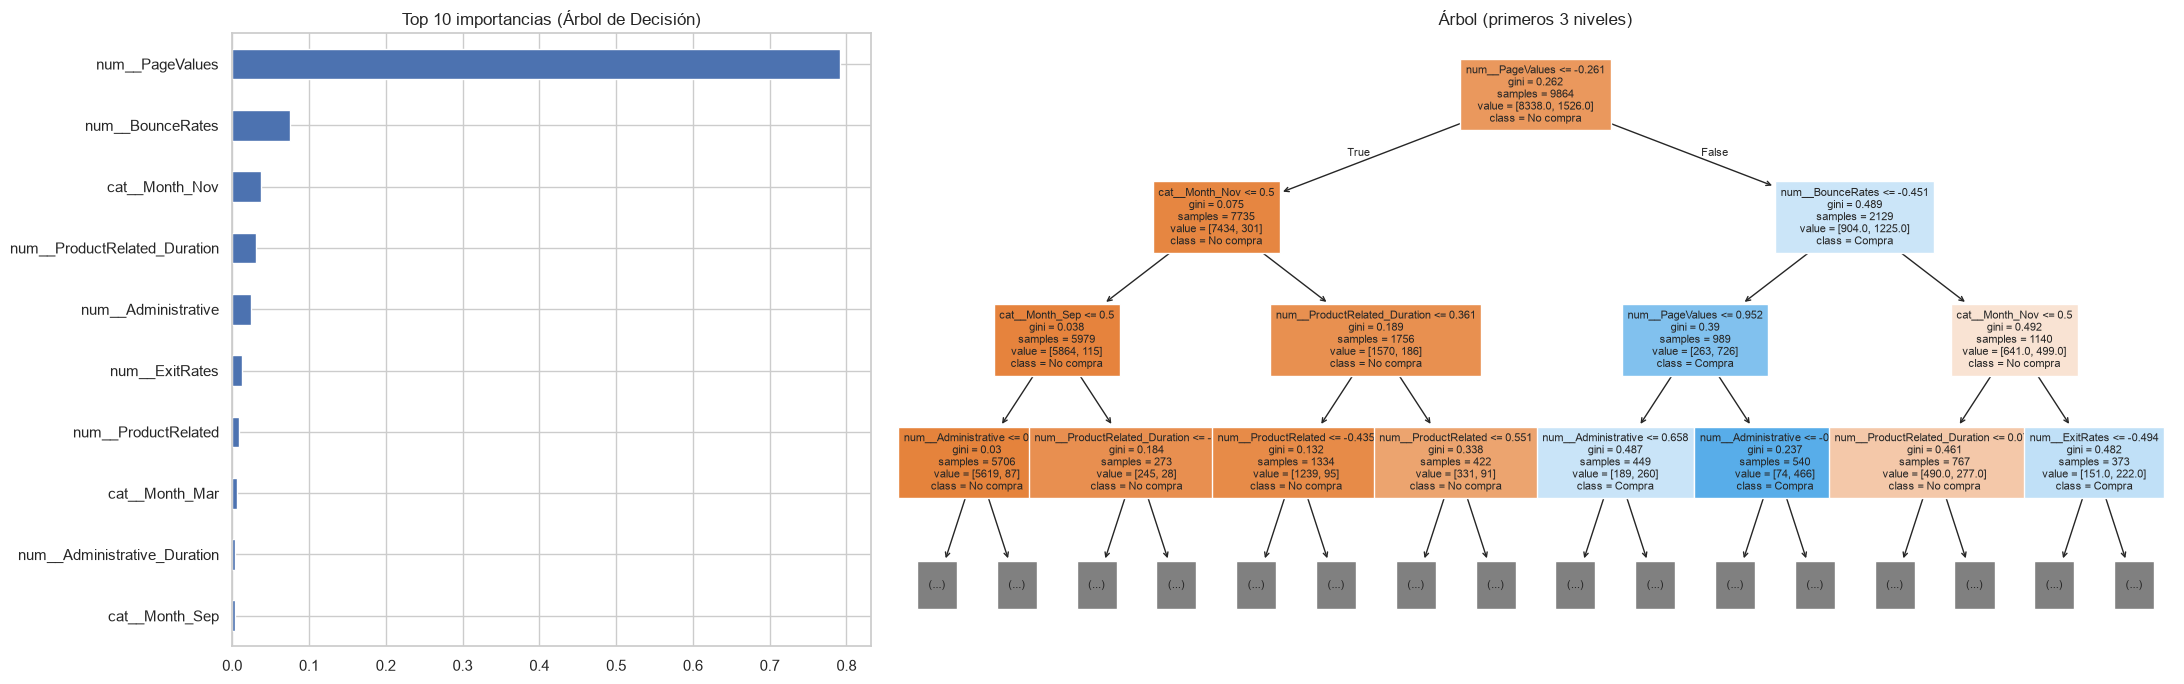

In [36]:
# Interpretabilidad del árbol: variables más importantes y estructura (primeros niveles)
arbol = modelo_dt.named_steps['clf']
nombres_feat = modelo_dt.named_steps['prep'].get_feature_names_out()
importancias = pd.Series(arbol.feature_importances_, index=nombres_feat).sort_values(ascending=False).head(10)

fig, axes = plt.subplots(1, 2, figsize=(22, 7), gridspec_kw={'width_ratios': [1, 2]})
importancias[::-1].plot(kind='barh', ax=axes[0], title="Top 10 importancias (Árbol de Decisión)")
plot_tree(arbol, max_depth=3, feature_names=nombres_feat, class_names=['No compra', 'Compra'],
          filled=True, fontsize=8, ax=axes[1])
axes[1].set_title("Árbol (primeros 3 niveles)")
plt.tight_layout()
plt.show()

<h4>Modelo seleccionado y justificación</h4>
<p><i>(Confirmar con los resultados obtenidos.)</i> Lo habitual con este dataset es que el <b>Árbol de Decisión</b> supere claramente a Naive Bayes en exactitud, precisión y F1, y sea más estable en la validación cruzada. Además, es interpretable: sus reglas muestran que <code>PageValues</code> es el factor dominante, lo que permite explicar la predicción a un equipo de negocio. Naive Bayes sufre porque su supuesto de independencia no se cumple (<code>BounceRates</code>/<code>ExitRates</code> correlacionadas, muchas variables dummy). Si Naive Bayes mostrara un recall notablemente más alto, habría que ponderarlo según el costo del negocio (ver siguiente pregunta). Se selecciona el modelo con mejor F1 y estabilidad en CV, justificándolo con los números de las tablas anteriores.</p>

<h3>Pregunta de Análisis</h3>
<p><b>¿Qué consecuencias podrían tener los falsos positivos y los falsos negativos en el contexto del problema? ¿Qué métrica es más importante y por qué?</b></p>
<ul>
    <li><b>Falso positivo (se predice compra y no ocurre):</b> la tienda gasta recursos en una sesión que no iba a convertir: descuentos innecesarios (pérdida de margen), chats o pop-ups intrusivos que pueden molestar al usuario, o campañas de remarketing mal dirigidas. También puede generar una visión demasiado optimista de la demanda (p. ej., planificar inventario de más).</li>
    <li><b>Falso negativo (se predice no compra y sí compra, o habría comprado con un pequeño incentivo):</b> se pierde la oportunidad de intervenir en usuarios con alta intención de compra (no ofrecer ayuda, envío gratis o recordatorios), con pérdida directa de ingresos. Si el modelo se usa para descartar sesiones, también se subestima la demanda.</li>
    <li><b>Métrica prioritaria:</b> dado que la clase de interés es minoritaria (~15 %), la exactitud es engañosa. Si las intervenciones son baratas (mostrar un banner, enviar un correo), el costo de un FN (venta perdida) supera al de un FP, por lo que priorizaríamos el <b>recall</b> de la clase "compra" sin dejar que la precisión se desplome. Si las intervenciones son costosas (descuentos fuertes), se priorizaría la <b>precisión</b>. Como equilibrio general, el <b>F1-score</b> de la clase positiva es la métrica de referencia más razonable. Con ese criterio, el umbral de decisión también puede ajustarse (p. ej. con <code>predict_proba</code>) según el costo real de cada error.</li>
</ul>